# Thống kê tập dữ liệu NIH ChestX-ray14

## 0. Khởi tạo

In [1]:
# Hiển thị hình ngay dưới ô code tạo ra nó
## Thiếu dòng này, một số trình chạy notebook (VS Code, nbclient) không bật chế độ tự hiển thị:
## chỉ hình đầu tiên hiện đúng chỗ, các hình sau dồn xuống ô có plt.show() kế tiếp
%matplotlib inline
## Hình hiển thị trong notebook cũng bo sát nội dung (lề 0.08 inch, đủ để chữ trục dọc không bị xén), giống file PNG lưu ra
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pad_inches": 0.08}

# Khai báo utilities: tìm thư mục train_models (chứa config.py) và thêm vào sys.path
import sys
from pathlib import Path
ROOT_DIR = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "config.py").exists())
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

# Khai báo thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from utilities import charts
from analysis import nih_statistics as nih

# Cấu hình
DATASET_NAME    = "nih_chestxray_14"
SAVE            = True                                                      # True: lưu PNG vào statistics/charts/<tên tập dữ liệu>
CHART_DIRECTORY = ROOT_DIR / "statistics" / "charts" / DATASET_NAME
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Đường dẫn lưu một biểu đồ (None khi không lưu)
def output(name):
    return CHART_DIRECTORY / f"{name}.png" if SAVE else None

In [1]:
# Đọc metadata và tính các bảng
df      = nih.load_metadata()
tables  = nih.compute_tables(df)
print(f"{charts.format_number(len(df))} ảnh, {charts.format_number(df[nih.PATIENT].nunique())} bệnh nhân")

112,120 ảnh, 30,805 bệnh nhân


## 1. Cách chia tập chính thức
Chương 4: đoạn đầu mục *Thống kê tập dữ liệu*.

In [2]:
# Quy mô hai tập và kiểm tra rò rỉ bệnh nhân giữa hai tập
display(charts.format_table(tables["overview"].loc[["Số ảnh", "Số bệnh nhân"]]))
print("Bệnh nhân có mặt ở cả hai tập:", tables["quality"].loc["Bệnh nhân có mặt ở cả hai tập", "Giá trị"])

,Huấn luyện,Kiểm tra,Tổng
Số ảnh,"86,524","25,596","112,120"
Số bệnh nhân,"28,008","2,797","30,805"


Bệnh nhân có mặt ở cả hai tập: 0


## 2. Số nhãn bệnh lý trên mỗi ảnh

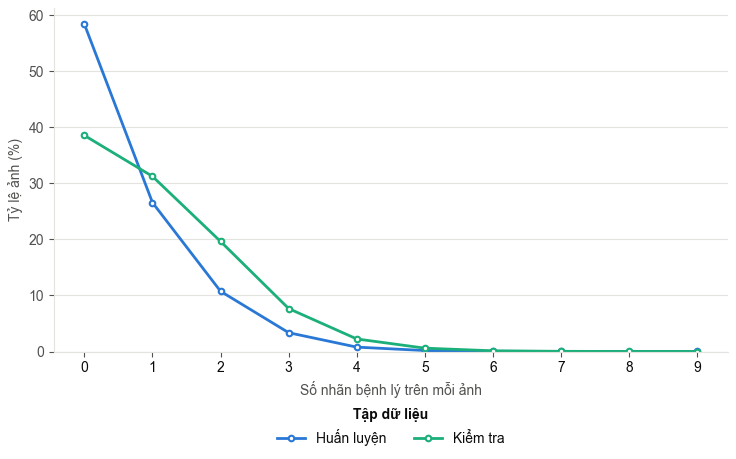

In [3]:
table = tables["labels_per_image"]
display(charts.format_table(table))

charts.line(nih.percent(table, nih.SPLITS), x_label = "Số nhãn bệnh lý trên mỗi ảnh", y_label = "Tỷ lệ ảnh (%)", output = output("2_labels_per_image"));

In [4]:
# Các số liệu dẫn trong phần nhận xét của Chương 4 (tính từ bảng trên)
count   = nih.counts(table, nih.SPLITS)                                     # [số nhãn x tập], không gồm hàng Tổng
share   = nih.percent(table, nih.SPLITS)
summary = pd.DataFrame({
    "Ảnh 0 nhãn (No Finding) (%)":      share.loc[0],
    "Ảnh 1 nhãn (%)":                   share.loc[1],
    "Ảnh ≥ 2 nhãn (%)":                 share.loc[2:].sum(),
    "Ảnh 2–3 nhãn (%)":                 share.loc[2:3].sum(),
    "Ảnh ≥ 4 nhãn (%)":                 share.loc[4:].sum(),
    "Ảnh ≥ 5 nhãn (số ảnh)":            count.loc[5:].sum(),
    "Ảnh ≥ 5 nhãn (%)":                 share.loc[5:].sum(),
    "Số nhãn tối đa trên một ảnh":      count.apply(lambda column: column[column > 0].index.max()),
    "Số nhãn TB trên ảnh có bệnh lý":   tables["overview"].loc["Nhãn / ảnh có bệnh (TB)", nih.SPLITS].astype(float),
}).T
display(charts.format_table(summary, axis = 1))

,Huấn luyện,Kiểm tra
Ảnh 0 nhãn (No Finding) (%),58.37,38.53
Ảnh 1 nhãn (%),26.55,31.22
Ảnh ≥ 2 nhãn (%),15.09,30.25
Ảnh 2–3 nhãn (%),14.08,27.27
Ảnh ≥ 4 nhãn (%),1.01,2.98
Ảnh ≥ 5 nhãn (số ảnh),195,192
Ảnh ≥ 5 nhãn (%),0.23,0.75
Số nhãn tối đa trên một ảnh,9,8
Số nhãn TB trên ảnh có bệnh lý,1.50,1.73


## 3. Số ảnh trên mỗi bệnh nhân

### 3.1. Theo nhóm số ảnh

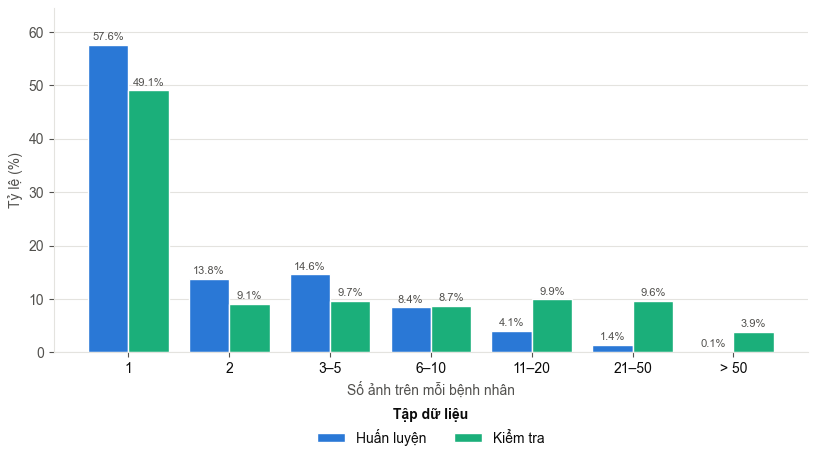

In [5]:
table = tables["images_per_patient"]
display(charts.format_table(table))

percent, labels = nih.percent_with_labels(table)
charts.bar(percent, labels, x_label = "Số ảnh trên mỗi bệnh nhân", y_label = "Tỷ lệ (%)", output = output("3.1_images_per_patient"));

In [6]:
# Các số liệu dẫn trong phần nhận xét của Chương 4: trung bình, trung vị, lớn nhất, số bệnh nhân có > 100 ảnh
summary     = tables["overview"].loc[["Ảnh / bệnh nhân (TB)", "Ảnh / bệnh nhân (trung vị)", "Ảnh / bệnh nhân (tối đa)"]].astype(float)
per_patient = df.groupby(nih.PATIENT).agg(split = (nih.SPLIT, "first"), images = (nih.PATIENT, "size"))     # Mỗi bệnh nhân chỉ thuộc một tập (mục 1)
over_100    = per_patient.loc[per_patient["images"] > 100, "split"].astype(str).value_counts()
summary.loc["Số bệnh nhân có > 100 ảnh"] = [over_100.get(split, 0) for split in nih.SPLITS] + [over_100.sum()]
display(charts.format_table(summary, axis = 1))

,Huấn luyện,Kiểm tra,Tổng
Ảnh / bệnh nhân (TB),3.09,9.15,3.64
Ảnh / bệnh nhân (trung vị),1,2,1
Ảnh / bệnh nhân (tối đa),109,184,184
Số bệnh nhân có > 100 ảnh,2,16,18


### 3.2. Không gom nhóm (thang log)

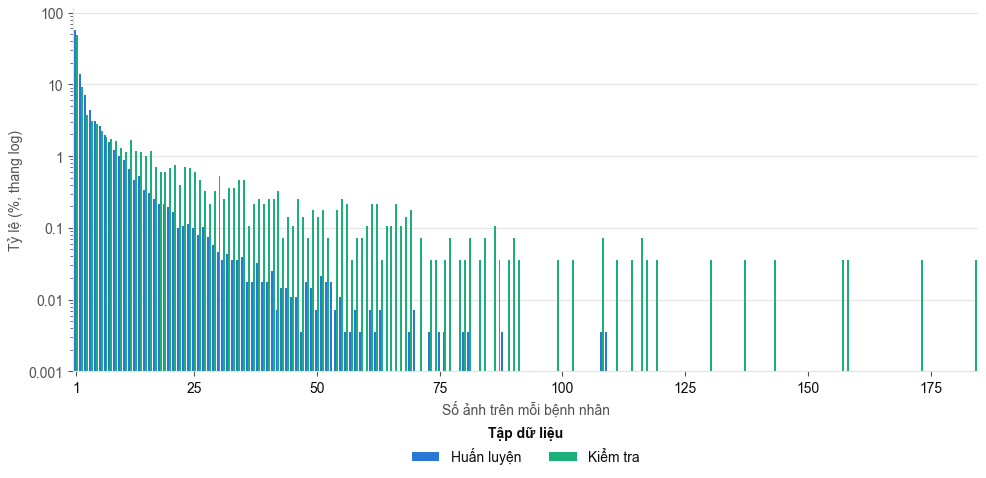

In [7]:
# Đủ mọi giá trị k từ 1 tới lớn nhất (k không có bệnh nhân = 0) để trục số ảnh cách đều; chỉ ghi mốc 1, 25, 50, ...
values  = nih.percent(tables["images_per_patient_exact"], nih.SPLITS)
values  = values.reindex(range(1, values.index.max() + 1), fill_value = 0)
ticks   = [1] + list(range(25, values.index.max() + 1, 25))
charts.bar(values, ticks = ticks, edge = False, log = True, figure_size = (10, 4.4),
           x_label = "Số ảnh trên mỗi bệnh nhân", y_label = "Tỷ lệ (%, thang log)", output = output("3.2_images_per_patient_exact_log"));

### 3.3. Tính theo bệnh nhân và tính theo ảnh

Số ảnh / bệnh nhân,Số bệnh nhân,Tỷ lệ bệnh nhân (%),Số ảnh,Tỷ lệ ảnh (%)
1,"16,130",57.59,"16,130",18.64
2–5,"7,956",28.41,"22,971",26.55
6–20,"3,497",12.49,"33,838",39.11
> 20,425,1.52,"13,585",15.70
Tổng,"28,008",100.00,"86,524",100.00


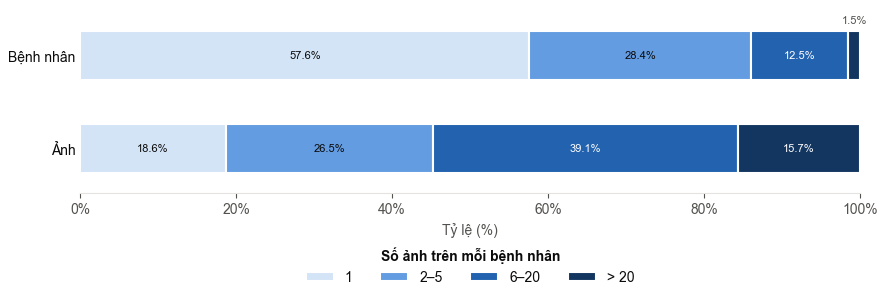

,Số bệnh nhân,Tỷ lệ bệnh nhân (%),Số ảnh,Tỷ lệ ảnh (%)
1,"1,373",49.09,"1,373",5.36
2–5,525,18.77,"1,565",6.11
6–20,521,18.63,"5,976",23.35
> 20,378,13.51,"16,682",65.17
Tổng,"2,797",100.00,"25,596",100.00


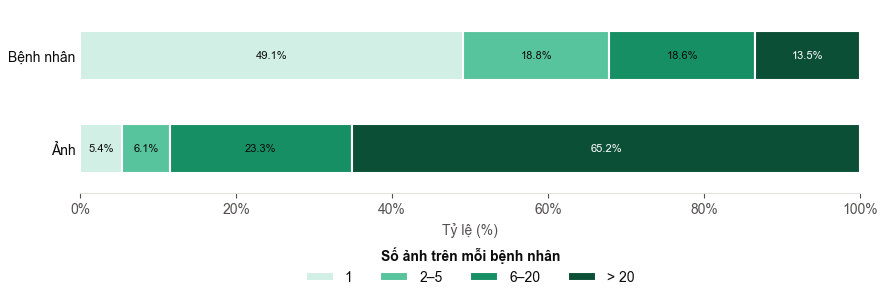

In [8]:
table = tables["patient_image_share"]
share = nih.share_percent(table)

# Mỗi tập một bảng và một hình, thang màu nhạt -> đậm theo màu đại diện của tập
for split, name in ((nih.TRAIN_VAL, "train"), (nih.TEST, "test")):
    display(charts.format_table(table[split]))
    charts.stacked(share.loc[split], color = charts.COLORS[split], x_label = "Tỷ lệ (%)", legend_title = "Số ảnh trên mỗi bệnh nhân",
                   figure_size = (9, 2.6), output = output(f"3.3_patient_image_share_{name}"))
    plt.show()

## 4. Tỷ lệ ảnh dương tính của từng nhãn

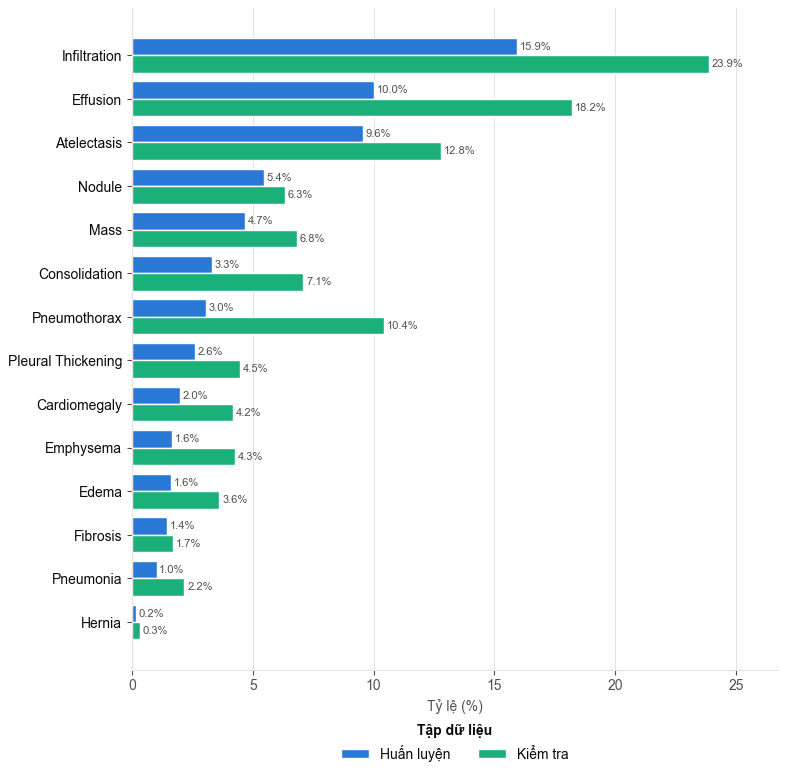

In [9]:
table = tables["label_images"]
display(charts.format_table(table))

percent, labels = nih.percent_with_labels(table.loc[nih.CLASSES].sort_values((nih.TRAIN_VAL, nih.PERCENT), ascending = False))
charts.bar(percent, labels, horizontal = True, x_label = "Tỷ lệ (%)", output = output("4_label_images"));

In [10]:
# Mức tăng tỷ lệ dương tính từ Huấn luyện sang Kiểm tra (số lần), sắp giảm dần
increase = (percent[nih.TEST] / percent[nih.TRAIN_VAL]).sort_values(ascending = False)
display(charts.format_table(increase.rename("Kiểm tra / Huấn luyện (lần)").to_frame(), max_decimals = 1))

,Kiểm tra / Huấn luyện (lần)
Pneumothorax,3.4
Emphysema,2.6
Edema,2.3
Consolidation,2.2
Pneumonia,2.1
Cardiomegaly,2.1
Hernia,2.1
Effusion,1.8
Pleural Thickening,1.7
Infiltration,1.5


## 5. Mất cân bằng nhãn trên tập Huấn luyện

,Số ảnh dương,Số ảnh âm,Tỷ lệ mất cân bằng
Infiltration,"13,782","72,742",5.3
Effusion,"8,659","77,865",9.0
Atelectasis,"8,280","78,244",9.4
Nodule,"4,708","81,816",17.4
Mass,"4,034","82,490",20.4
Consolidation,"2,852","83,672",29.3
Pneumothorax,"2,637","83,887",31.8
Pleural Thickening,"2,242","84,282",37.6
Cardiomegaly,"1,707","84,817",49.7
Emphysema,"1,423","85,101",59.8


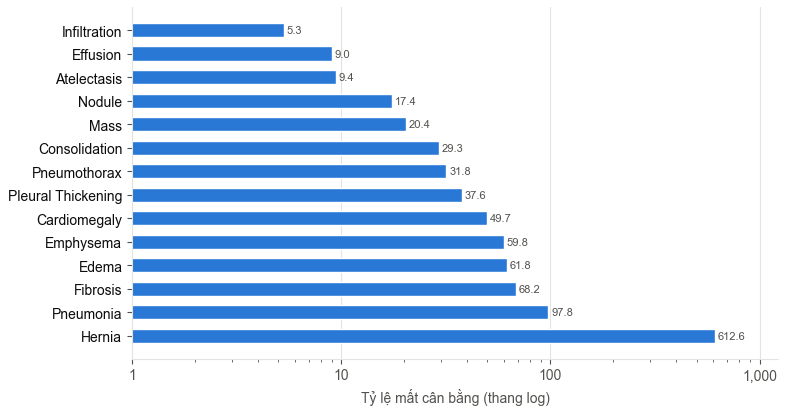

In [11]:
table = tables["imbalance"]
display(charts.format_table(table))

ratio = table[nih.IMBALANCE].rename(nih.TRAIN_VAL)                         # Tên dãy = tên tập để giữ đúng màu của tập
charts.bar(ratio, ratio.map(lambda value: charts.format_number(value, 1)), horizontal = True, log = True,
           x_label = "Tỷ lệ mất cân bằng (thang log)", output = output("5_imbalance"));

In [12]:
# Các số liệu dẫn trong phần nhận xét của Chương 4
no_finding = tables["label_images"].loc[nih.NO_FINDING, (nih.TRAIN_VAL, nih.PERCENT)]
print(f"Hiếm nhất / phổ biến nhất: {ratio.max()} / {ratio.min()} = {ratio.max() / ratio.min():.1f} lần")
print(f"Ảnh No Finding trên tập Huấn luyện: {charts.format_percent(no_finding, 2)}")

Hiếm nhất / phổ biến nhất: 612.6 / 5.3 = 115.6 lần
Ảnh No Finding trên tập Huấn luyện: 58.37%
